# Pipeline Final

Nesse notebook iremos fazer a execução fim-a-fim do Projeto Integrador

1. Extração e Transformação dos Dados
2. Salvar os arquivos processados para uso futuro
3. Transformações para o Modelo de PLN
4. Treino do modelo de PLN
5. Salvar o modelo treinado para uso futuro

## 1. Extração e Transformação

In [96]:
!pip install github-content-downloader

In [97]:
### 1.1 Preparação do Ambiente

import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import nltk
import pandas as pd
import seaborn as sns
import shutil
import tensorflow as tf

from github_downloader import download_from_github
from google.colab import files

from nltk.tokenize import word_tokenize
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Baixar pacotes necessários do NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Fallback de funções e variáveis caso não estejam carregadas na memória ativa
def remove_stopwords_and_stem(words):
    return [w.lower() for w in words if len(w) > 2]

# Definir diretório de imagens padrão se não definido
images_dir = globals().get('images_dir', '/content/data/raw/images')
os.makedirs(images_dir, exist_ok=True)

# Definir caminhos
raw_data_path = (
    'https://raw.githubusercontent.com/'
    'especializacao-ia-pucsp/'
    'grupo-01-projeto_supervisionado-II/'
    'refs/heads/main/data/raw/chamados.csv'
)
preprocessed_dir = '/content/data/preprocessed'
os.makedirs(preprocessed_dir, exist_ok=True)

### 1.2 Carregar dados brutos
print("Lendo o dataset bruto...")
df_raw = pd.read_csv(raw_data_path)
download_from_github(
    (
        "https://github.com/"
        "especializacao-ia-pucsp/"
        "grupo-01-projeto_supervisionado-II/"
        "tree/main/data/raw/images"
    ),
    dest_folder=images_dir
)

### 1.3 Evitar que as colunas `title` e `description` estejam vazias
df_raw['title'] = df_raw['title'].astype(str).fillna('')
df_raw['description'] = df_raw['description'].astype(str).fillna('')

### 1.4. Pré-processamento e vetorização de texto
print("Pré-processando o texto...")
df_raw['title_words'] = df_raw['title'].apply(word_tokenize)
df_raw['description_words'] = df_raw['description'].apply(word_tokenize)

df_raw['title_stemmed'] = df_raw['title_words'].apply(remove_stopwords_and_stem)
df_raw['description_stemmed'] = df_raw['description_words'].apply(remove_stopwords_and_stem)

df_raw['title_stemmed_str'] = df_raw['title_stemmed'].apply(lambda x: ' '.join(x))
df_raw['description_stemmed_str'] = df_raw['description_stemmed'].apply(lambda x: ' '.join(x))

### 1.5. Sequências numéricas e preenchimento (padding)
print("Convertendo textos para sequências...")
title_seqs = [[title_word_index.get(word, 0) for word in text.split()] for text in df_raw['title_stemmed_str']]
desc_seqs = [[description_word_index.get(word, 0) for word in text.split()] for text in df_raw['description_stemmed_str']]

padded_titles = pad_sequences(title_seqs, maxlen=max_title_len, padding='post', truncating='post')
padded_descs = pad_sequences(desc_seqs, maxlen=max_description_len, padding='post', truncating='post')

### 1.6. Encodar os Rótulos
le = LabelEncoder()
le.fit_transform(df_raw['target_category'])

""" Dada a baixa performance da Visão Computacional,
    removemos a etapa de pré-processamento e vetorização de imagens.
    Está comentado porque pode ser alterado no futuro
    (e é bom não perder o código)

### 1.7. Estruturar caminhos e pré-processar as Imagens brutas
print("Processando imagens físicas para a model_vision...")
if 'image_path' in df_raw.columns:
    df_raw['full_image_path'] = df_raw['image_path'].apply(lambda x: os.path.join(images_dir, os.path.basename(str(x))))
else:
    df_raw['full_image_path'] = ''

image_arrays = []
for idx, img_path in enumerate(df_raw['full_image_path']):
    try:
        img = load_img(img_path, target_size=(224, 224))
        img_arr = img_to_array(img)
        img_preprocessed = preprocess_input(img_arr)
        image_arrays.append(img_preprocessed)
    except Exception as e:
        # Fallback de imagem em branco caso haja falha de carregamento ou arquivo ausente
        image_arrays.append(np.zeros((224, 224, 3)))

images_preprocessed = np.array(image_arrays)
"""


Lendo o dataset bruto...
Downloaded: /content/images/access_denied.png
Downloaded: /content/images/browser.png
Downloaded: /content/images/cooler.png
Downloaded: /content/images/default_access.png
Downloaded: /content/images/default_finance.png
Downloaded: /content/images/default_hardware.png
Downloaded: /content/images/default_hr.png
Downloaded: /content/images/default_network.png
Downloaded: /content/images/default_software.png
Downloaded: /content/images/email.png
Downloaded: /content/images/finance_report.png
Downloaded: /content/images/hard_drive.png
Downloaded: /content/images/hr_portal.png
Downloaded: /content/images/keyboard.png
Downloaded: /content/images/login.png
Downloaded: /content/images/monitor.png
Downloaded: /content/images/motherboard.png
Downloaded: /content/images/mouse.png
Downloaded: /content/images/network.png
Downloaded: /content/images/office.png
Downloaded: /content/images/payroll.png
Downloaded: /content/images/power_supply.png
Downloaded: /content/images/rec

' Dada a baixa performance da Visão Computacional, \n    removemos a etapa de pré-processamento e vetorização de imagens.\n    Está comentado porque pode ser alterado no futuro \n    (e é bom não perder o código)\n    \n### 1.7. Estruturar caminhos e pré-processar as Imagens brutas\nprint("Processando imagens físicas para a model_vision...")\nif \'image_path\' in df_raw.columns:\n    df_raw[\'full_image_path\'] = df_raw[\'image_path\'].apply(lambda x: os.path.join(images_dir, os.path.basename(str(x))))\nelse:\n    df_raw[\'full_image_path\'] = \'\'\n\nimage_arrays = []\nfor idx, img_path in enumerate(df_raw[\'full_image_path\']):\n    try:\n        img = load_img(img_path, target_size=(224, 224))\n        img_arr = img_to_array(img)\n        img_preprocessed = preprocess_input(img_arr)\n        image_arrays.append(img_preprocessed)\n    except Exception as e:\n        # Fallback de imagem em branco caso haja falha de carregamento ou arquivo ausente\n        image_arrays.append(np.zeros

## 2. Salvar os Arquivos Pré-processados

In [98]:
### 2.1. Salvar os dados processados para inspeção e uso nos próximos passos
print("Salvando dados estruturados pré-processados...")
df_raw.to_csv(os.path.join(preprocessed_dir, 'df_preprocessed.csv'), index=False)
np.savez_compressed(os.path.join(preprocessed_dir, 'images_preprocessed.npz'), data=images_preprocessed)
joblib.dump(le, os.path.join(preprocessed_dir, 'label_encoder.joblib'))

print(f"Sucesso absoluto! Todas as imagens e textos pré-processados salvos em: '{preprocessed_dir}'")



Salvando dados estruturados pré-processados...
Sucesso absoluto! Todas as imagens e textos pré-processados salvos em: '/content/data/preprocessed'


In [99]:
### 2.2. Definição dos caminhos das pastas e arquivos
preprocessed_dir = '/content/data/preprocessed'
model_text_path = 'mlp_emb.joblib'

### 2.3. Carregando os Metadados e o Label Encoder
print("Carregando estruturas de suporte...")
df = pd.read_csv(os.path.join(preprocessed_dir, 'df_preprocessed.csv'))
le = joblib.load(os.path.join(preprocessed_dir, 'label_encoder.joblib'))

""" Não estamos mais gerando as imagens
### 2.4. Carregando os arrays Numpy pré-processados
with np.load(os.path.join(preprocessed_dir, 'images_preprocessed.npz')) as raw_npz:
    images_preprocessed = raw_npz['data']
"""

print(f"✓ Dados carregados: DataFrame {df.shape}") # | Imagens {images_preprocessed.shape}")


Carregando estruturas de suporte...
✓ Dados carregados: DataFrame (5000, 50)


## 3. Transformações para o Modelo de PLN



In [100]:
### 3.1. Preparar dados para a Camada de Embedding
title_word_index = {word: idx + 1 for idx, word in enumerate(title_count_vectorizer.get_feature_names_out())}
description_word_index = {word: idx + 1 for idx, word in enumerate(description_count_vectorizer.get_feature_names_out())}

### 3.2. Converter texto para sequências de inteiros
title_sequences = [[title_word_index.get(word, 0) for word in text.split()] for text in df['title_stemmed_str']]
description_sequences = [[description_word_index.get(word, 0) for word in text.split()] for text in df['description_stemmed_str']]

### 3.3. Determinar comprimento máximo para padding
max_title_len = max(len(seq) for seq in title_sequences) if title_sequences else 1
max_description_len = max(len(seq) for seq in description_sequences) if description_sequences else 1

### 3.4. Aplicar padding às sequências
padded_title_sequences = pad_sequences(title_sequences, maxlen=max_title_len, padding='post', truncating='post')
padded_description_sequences = pad_sequences(description_sequences, maxlen=max_description_len, padding='post', truncating='post')

### 3.5. Definir um modelo simples com uma Camada de Embedding
vocab_size_title = len(title_word_index) + 1 # +1 para o índice 0 (padding/palavras desconhecidas)
vocab_size_description = len(description_word_index) + 1
embedding_dim = 100 # Dimensão dos vetores de embedding

### 3.6. Modelo de Embedding para títulos
title_embedding_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=vocab_size_title, output_dim=embedding_dim, input_length=max_title_len),
    tf.keras.layers.GlobalAveragePooling1D() # Para obter um embedding de documento de tamanho fixo
])

### 3.7. Modelo de Embedding para descrições
description_embedding_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=vocab_size_description, output_dim=embedding_dim, input_length=max_description_len),
    tf.keras.layers.GlobalAveragePooling1D() # Para obter um embedding de documento de tamanho fixo
])

### 3.8. Gerar Embeddings
print("\nGerando embeddings para títulos...")
title_embeddings = title_embedding_model.predict(padded_title_sequences)
print(f"Shape dos embeddings de títulos: {title_embeddings.shape}")

print("Gerando embeddings para descrições...")
description_embeddings = description_embedding_model.predict(padded_description_sequences)
print(f"Shape dos embeddings de descrições: {description_embeddings.shape}")

### 3.9. Monta os DataFrames de embeddings já com o ticket_id como identificador
df_title_embeddings = pd.DataFrame(
    title_embeddings,
    columns=[f'title_emb_{i}' for i in range(title_embeddings.shape[1])]
)
df_title_embeddings.insert(0, 'ticket_id', df['ticket_id'].values)

df_description_embeddings = pd.DataFrame(
    description_embeddings,
    columns=[f'desc_emb_{i}' for i in range(description_embeddings.shape[1])]
)
df_description_embeddings.insert(0, 'ticket_id', df['ticket_id'].values)

### 3.10. Aplicar PCA
def aplicar_pca(embeddings, nome, variancia_desejada=0.80):
    # PCA com número de componentes que preserva a variância desejada
    pca = PCA(n_components=variancia_desejada, svd_solver='full', random_state=42)
    embeddings_reduzidos = pca.fit_transform(embeddings)

    print(f"[{nome}] Dimensão original: {embeddings.shape[1]}")
    print(f"[{nome}] Dimensão após PCA ({variancia_desejada*100:.0f}% da variância): {embeddings_reduzidos.shape[1]}")

    return pca, embeddings_reduzidos

pca_title, title_embeddings_pca = aplicar_pca(title_embeddings, 'Título')
pca_description, description_embeddings_pca = aplicar_pca(description_embeddings, 'Descrição')

df_title_embeddings_pca = pd.DataFrame(
    title_embeddings_pca,
    columns=[f'title_pca_{i}' for i in range(title_embeddings_pca.shape[1])]
)
df_title_embeddings_pca.insert(0, 'ticket_id', df['ticket_id'].values)

df_description_embeddings_pca = pd.DataFrame(
    description_embeddings_pca,
    columns=[f'desc_pca_{i}' for i in range(description_embeddings_pca.shape[1])]
)
df_description_embeddings_pca.insert(0, 'ticket_id', df['ticket_id'].values)

### 3.11. Junta as versões reduzidas por PCA de volta ao df principal, usando ticket_id
df = df.merge(df_title_embeddings_pca, on='ticket_id', how='left')
df = df.merge(df_description_embeddings_pca, on='ticket_id', how='left')

print(f"Shape de df após o merge: {df.shape}")
display(df.head())

assert df.shape[0] == 5000, f"Esperado 5000 linhas, veio {df.shape[0]}"
assert df.filter(like='title_pca_').isnull().sum().sum() == 0, "Há tickets sem embedding de título"
assert df.filter(like='desc_pca_').isnull().sum().sum() == 0, "Há tickets sem embedding de descrição"
print("OK — merge íntegro, sem duplicatas ou nulos.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Gerando embeddings para títulos...
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Shape dos embeddings de títulos: (5000, 100)
Gerando embeddings para descrições...
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Shape dos embeddings de descrições: (5000, 100)
[Título] Dimensão original: 100
[Título] Dimensão após PCA (80% da variância): 23
[Descrição] Dimensão original: 100
[Descrição] Dimensão após PCA (80% da variância): 22
Shape de df após o merge: (5000, 95)


,ticket_id,created_at,customer_id,department,city_x,state_x,device_type,os,browser,network_type,...,desc_pca_12,desc_pca_13,desc_pca_14,desc_pca_15,desc_pca_16,desc_pca_17,desc_pca_18,desc_pca_19,desc_pca_20,desc_pca_21
0,1,2025-01-01T00:17:00,5012,Operações,Campinas,BA,Desktop,Windows,Safari,WiFi,...,0.000046,0.024528,-0.020156,-0.012165,0.001121,-0.017532,-0.000820,0.000904,0.014968,0.010841
1,2,2025-01-01T00:34:00,6574,Financeiro,Campinas,RJ,Notebook,Windows,Chrome,5G,...,-0.005913,-0.001353,0.001220,0.016947,0.004062,0.002619,0.003916,0.002120,0.000479,-0.005991
2,3,2025-01-01T00:51:00,2139,TI,Campinas,MG,Desktop,Linux,Chrome,5G,...,-0.007953,-0.000463,-0.005609,-0.024399,0.000866,0.000864,-0.000206,-0.012622,-0.009402,-0.022884
3,4,2025-01-01T01:08:00,7216,Financeiro,Belo Horizonte,RJ,Mobile,Android,Chrome,Cabo,...,-0.003207,-0.018592,0.021879,-0.016391,0.001032,0.004148,-0.009431,-0.004775,0.005783,0.006406
4,5,2025-01-01T01:25:00,5040,Financeiro,Belo Horizonte,PR,Mobile,iOS,Edge,Cabo,...,0.016522,0.007704,-0.003777,-0.004670,-0.002646,0.012729,0.014704,-0.003871,0.010209,-0.001842


OK — merge íntegro, sem duplicatas ou nulos.


In [101]:
# 3.12. Salvar os dados já processados
processed_dir = '/content/data/processed'
os.makedirs(processed_dir, exist_ok=True)

output_csv_path = os.path.join(processed_dir, 'chamados.csv')
df.to_csv(output_csv_path, index=False)

print(f"DataFrame salvo com sucesso em: '{output_csv_path}'")

DataFrame salvo com sucesso em: '/content/data/processed/chamados.csv'


## 4. Treino do modelo de PLN

In [102]:
### 4.1. Carregando os dados processados
processed_csv_path = '/content/data/processed/chamados.csv'
if os.path.exists(processed_csv_path):
    df = pd.read_csv(processed_csv_path)
    print(f"DataFrame carregado com sucesso de '{processed_csv_path}'! Formato: {df.shape}")
    display(df.head())
else:
    print(f"Erro: O arquivo '{processed_csv_path}' não foi encontrado.")

### 4.2. Separando os dados em treino, validação e testes
X_index = df.index.values

idx_treino_val, idx_teste = train_test_split(
    X_index, test_size=0.10, random_state=42, stratify=y
)
idx_treino, idx_val = train_test_split(
    idx_treino_val, test_size=0.111, random_state=42, stratify=y[idx_treino_val]
)  # 0.111 de 90% ≈ 10% do total

print(f"Treino: {len(idx_treino)} | Validação: {len(idx_val)} | Teste: {len(idx_teste)}")

DataFrame carregado com sucesso de '/content/data/processed/chamados.csv'! Formato: (5000, 95)


,ticket_id,created_at,customer_id,department,city_x,state_x,device_type,os,browser,network_type,...,desc_pca_12,desc_pca_13,desc_pca_14,desc_pca_15,desc_pca_16,desc_pca_17,desc_pca_18,desc_pca_19,desc_pca_20,desc_pca_21
0,1,2025-01-01T00:17:00,5012,Operações,Campinas,BA,Desktop,Windows,Safari,WiFi,...,0.000046,0.024528,-0.020156,-0.012165,0.001121,-0.017532,-0.000820,0.000904,0.014968,0.010841
1,2,2025-01-01T00:34:00,6574,Financeiro,Campinas,RJ,Notebook,Windows,Chrome,5G,...,-0.005913,-0.001353,0.001220,0.016947,0.004062,0.002619,0.003916,0.002120,0.000479,-0.005991
2,3,2025-01-01T00:51:00,2139,TI,Campinas,MG,Desktop,Linux,Chrome,5G,...,-0.007953,-0.000463,-0.005609,-0.024399,0.000866,0.000864,-0.000206,-0.012622,-0.009402,-0.022884
3,4,2025-01-01T01:08:00,7216,Financeiro,Belo Horizonte,RJ,Mobile,Android,Chrome,Cabo,...,-0.003207,-0.018592,0.021879,-0.016391,0.001032,0.004148,-0.009431,-0.004775,0.005783,0.006406
4,5,2025-01-01T01:25:00,5040,Financeiro,Belo Horizonte,PR,Mobile,iOS,Edge,Cabo,...,0.016522,0.007704,-0.003777,-0.004670,-0.002646,0.012729,0.014704,-0.003871,0.010209,-0.001842


Treino: 4000 | Validação: 500 | Teste: 500


In [103]:
### 4.3. Colunas de embeddings (PCA) já mergeadas no df
colunas_pca = [c for c in df.columns if c.startswith('title_pca_') or c.startswith('desc_pca_')]
print(f"{len(colunas_pca)} colunas de embeddings PCA")

X_emb_treino = df.loc[idx_treino, colunas_pca].values
X_emb_val    = df.loc[idx_val, colunas_pca].values
X_emb_teste  = df.loc[idx_teste, colunas_pca].values

scaler_emb = StandardScaler()
X_emb_treino_scaled = scaler_emb.fit_transform(X_emb_treino)
X_emb_val_scaled    = scaler_emb.transform(X_emb_val)
X_emb_teste_scaled  = scaler_emb.transform(X_emb_teste)

y_treino = y[idx_treino]
y_val    = y[idx_val]
y_teste  = y[idx_teste]

mlp_emb = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=200,
    max_iter=50,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42,
    verbose=True
)
mlp_emb.fit(X_emb_treino_scaled, y_treino)

y_pred_emb = mlp_emb.predict(X_emb_teste_scaled)
print(f"\nAcurácia (só embeddings PCA): {accuracy_score(y_teste, y_pred_emb):.4f}")
print(classification_report(y_teste, y_pred_emb, target_names=le.classes_))

45 colunas de embeddings PCA
Iteration 1, loss = 1.50874173
Validation score: 0.697500
Iteration 2, loss = 0.89468730
Validation score: 0.822500
Iteration 3, loss = 0.50001912
Validation score: 0.887500
Iteration 4, loss = 0.29466889
Validation score: 0.937500
Iteration 5, loss = 0.19479731
Validation score: 0.947500
Iteration 6, loss = 0.14108097
Validation score: 0.955000
Iteration 7, loss = 0.11041200
Validation score: 0.962500
Iteration 8, loss = 0.09085579
Validation score: 0.960000
Iteration 9, loss = 0.07960527
Validation score: 0.962500
Iteration 10, loss = 0.07036416
Validation score: 0.970000
Iteration 11, loss = 0.06552763
Validation score: 0.967500
Iteration 12, loss = 0.05872518
Validation score: 0.967500
Iteration 13, loss = 0.05471291
Validation score: 0.957500
Iteration 14, loss = 0.05335715
Validation score: 0.957500
Iteration 15, loss = 0.04931435
Validation score: 0.965000
Iteration 16, loss = 0.04734099
Validation score: 0.960000
Iteration 17, loss = 0.04581087
Vali

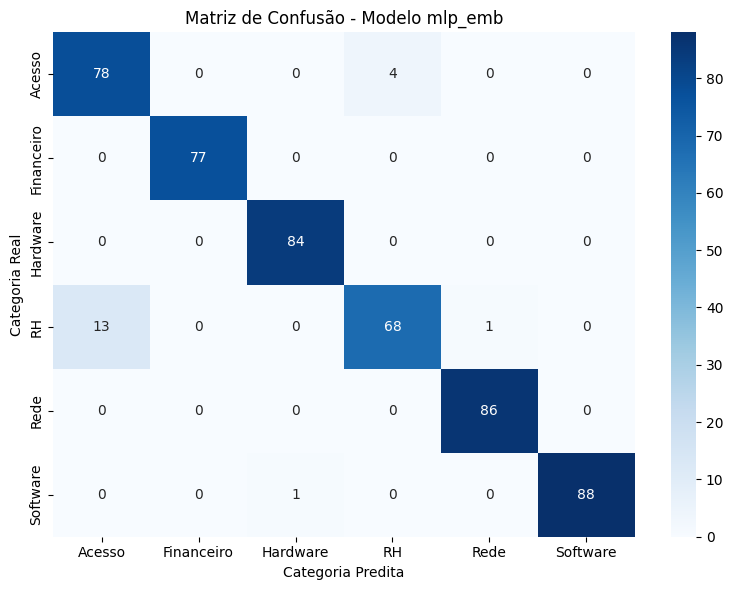

In [104]:
### 4.4. Calcular a matriz de confusão utilizando os rótulos reais e preditos do conjunto de teste
cm = confusion_matrix(y_teste, y_pred_emb)

### 4.5. Plotar a matriz usando seaborn para melhor legibilidade
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Matriz de Confusão - Modelo mlp_emb')
plt.ylabel('Categoria Real')
plt.xlabel('Categoria Predita')
plt.tight_layout()
plt.show()

## 5. Salvar o modelo treinado para uso futuro

In [105]:
### 5.1. Definir caminhos e criar o diretório de modelos se não existir
models_dir = '/content/data/models'
os.makedirs(models_dir, exist_ok=True)

### 5.2. Salvar o modelo mlp_emb treinado
model_save_path = os.path.join(models_dir, 'mlp_emb.joblib')
joblib.dump(mlp_emb, model_save_path)
print(f"✓ Modelo treinado salvo com sucesso em: '{model_save_path}'")

### 5.3. Criar uma pasta temporária para organizar o ZIP
zip_source_dir = '/content/temp_zip_dir'
os.makedirs(zip_source_dir, exist_ok=True)

### 5.4. Copiar as pastas models e processed para dentro da pasta temporária
if os.path.exists(models_dir):
    shutil.copytree(models_dir, os.path.join(zip_source_dir, 'models'), dirs_exist_ok=True)
if os.path.exists('/content/data/processed'):
    shutil.copytree('/content/data/processed', os.path.join(zip_source_dir, 'processed'), dirs_exist_ok=True)

### 5.5. Criar o arquivo ZIP
zip_output_path = '/content/processed_and_models'
shutil.make_archive(zip_output_path, 'zip', zip_source_dir)
print(f"✓ Arquivo ZIP criado com sucesso em: '{zip_output_path}.zip'")

### 5.6. Oferecer download do arquivo
files.download(f"{zip_output_path}.zip")

✓ Modelo treinado salvo com sucesso em: '/content/data/models/mlp_emb.joblib'
✓ Arquivo ZIP criado com sucesso em: '/content/processed_and_models.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>